# 06 — Threshold Optimization

## Objective
Explore how changing the Random Forest (Balanced) probability threshold changes fraud detection performance and investigation workload.

**Business context:** We receive approximately 10,000 claims per month and can investigate only 200. Our main operational strategy remains ranking claims by predicted fraud probability and selecting the top 200. Threshold analysis is complementary: it helps understand how a flagging rule behaves, what risk/alert volume it creates, and how different operating policies trade off precision and recall.

### Important evaluation design
- Create a validation set from the training data to explore thresholds and choose a threshold.
- Keep the original test set untouched until final evaluation.
- The threshold selected using F2 is an **illustrative recall-oriented policy**, not automatically the business-optimal policy.
- Fixed-capacity Top-K ranking remains our primary business decision metric.

### Questions
1. What happens to precision, recall, F1, and the number of flagged claims as the threshold changes?
2. Which threshold maximizes F2 on validation data (recall is weighted more heavily than precision)?
3. How does the selected threshold perform on the test set?
4. How does threshold-based flagging compare with Top-K investigation ranking?

## 1. Imports and project path

In [13]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, roc_auc_score, average_precision_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

search_start = Path.cwd().resolve()
project_root = None
for candidate in [search_start, *search_start.parents]:
    if (candidate / "data" / "processed" / "X_train.csv").exists():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Could not find data/processed/X_train.csv from current directory")

DATA_DIR = project_root / "data" / "processed"
REPORTS_DIR = project_root / "reports"
REPORTS_DIR.mkdir(exist_ok=True)
print("Project root:", project_root)

Project root: C:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection


## 2. Load the prepared train/test datasets

We reuse the feature-engineered data from Notebook 03. The original test set is held aside for final evaluation.

In [14]:
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Train fraud rate:", y_train.mean().round(4))
print("Test fraud rate:", y_test.mean().round(4))
print("Target counts in training data:")
print(y_train.value_counts())

X_train: (12336, 42)
X_test: (3084, 42)
Train fraud rate: 0.0598
Test fraud rate: 0.06
Target counts in training data:
FraudFound_P
0    11598
1      738
Name: count, dtype: int64


## 3. Create a validation split

We split the training data into a model-training subset and validation subset. Stratification preserves the fraud proportion in each subset.

In [15]:
X_model_train, X_val, y_model_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42, stratify=y_train
)

print("Model-training rows:", len(X_model_train))
print("Validation rows:", len(X_val))
print("Model-training fraud rate:", y_model_train.mean().round(4))
print("Validation fraud rate:", y_val.mean().round(4))

Model-training rows: 9868
Validation rows: 2468
Model-training fraud rate: 0.0598
Validation fraud rate: 0.06


## 4. Build the preprocessing pipeline and Random Forest

We replicate the winning model configuration from Notebook 05: Random Forest with `class_weight="balanced_subsample"`, 100 trees, `min_samples_leaf=2`, and `random_state=42`. Preprocessing is fitted only on the model-training subset.

In [16]:
numeric_features = X_model_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_model_train.select_dtypes(exclude=["number"]).columns.tolist()

def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ])

rf_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        n_jobs=1,
        random_state=42
    ))
])

rf_pipeline.fit(X_model_train, y_model_train)
print("Model trained.")

Model trained.


## 5. Generate validation probabilities

The probability score is the model’s estimated likelihood of the positive class (fraud). We will vary the threshold applied to these scores.

In [17]:
val_prob = rf_pipeline.predict_proba(X_val)[:, 1]
print("Probability range:", val_prob.min().round(4), "to", val_prob.max().round(4))
print("Validation AP / PR-AUC:", average_precision_score(y_val, val_prob))
print("Validation ROC-AUC:", roc_auc_score(y_val, val_prob))

Probability range: 0.0 to 0.7453
Validation AP / PR-AUC: 0.22455233729457766
Validation ROC-AUC: 0.8300457246039143


## 6. Evaluate a range of thresholds

At each threshold, a claim is flagged when its predicted probability is greater than or equal to the threshold. We also calculate F2, which weights recall more strongly than precision (beta=2).

In [18]:
thresholds = np.arange(0.01, 1.00, 0.01)
rows = []
for threshold in thresholds:
    pred = (val_prob >= threshold).astype(int)
    rows.append({
        "Threshold": threshold,
        "Flagged_Claims": int(pred.sum()),
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1": f1_score(y_val, pred, zero_division=0),
        "F2": fbeta_score(y_val, pred, beta=2, zero_division=0),
        "False_Positives": int(((pred == 1) & (y_val == 0)).sum()),
        "False_Negatives": int(((pred == 0) & (y_val == 1)).sum())
    })
threshold_results = pd.DataFrame(rows)
threshold_results.head()

,Threshold,Flagged_Claims,Accuracy,Precision,Recall,F1,F2,False_Positives,False_Negatives
0,0.01,1876,0.296596,0.076759,0.972973,0.142292,0.291734,1732,4
1,0.02,1604,0.406807,0.089776,0.972973,0.164384,0.327869,1460,4
2,0.03,1422,0.480551,0.101266,0.972973,0.183439,0.357498,1278,4
3,0.04,1313,0.524716,0.109673,0.972973,0.197125,0.377953,1169,4
4,0.05,1236,0.555916,0.116505,0.972973,0.208092,0.393873,1092,4


## 7. Visualize threshold trade-offs

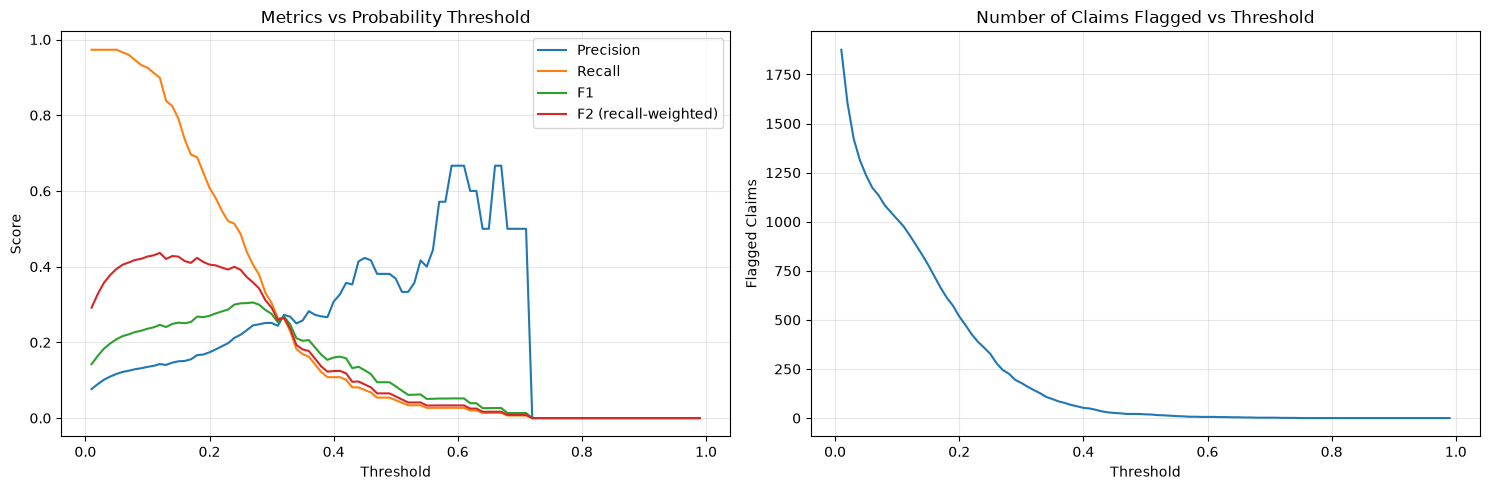

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(threshold_results["Threshold"], threshold_results["Precision"], label="Precision")
axes[0].plot(threshold_results["Threshold"], threshold_results["Recall"], label="Recall")
axes[0].plot(threshold_results["Threshold"], threshold_results["F1"], label="F1")
axes[0].plot(threshold_results["Threshold"], threshold_results["F2"], label="F2 (recall-weighted)")
axes[0].set_title("Metrics vs Probability Threshold")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Score")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(threshold_results["Threshold"], threshold_results["Flagged_Claims"])
axes[1].set_title("Number of Claims Flagged vs Threshold")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Flagged Claims")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Compare selected thresholds

Review thresholds such as 0.10, 0.20, 0.30, 0.40, and 0.50. These are examples for interpretation—not preselected answers. The flagged count is important because a lower threshold may produce a queue much larger than our team can investigate.

In [20]:
comparison_thresholds = [0.10, 0.20, 0.30, 0.40, 0.50]
comparison = threshold_results[threshold_results["Threshold"].round(2).isin(comparison_thresholds)].copy()
comparison[["Threshold", "Flagged_Claims", "Precision", "Recall", "F1", "F2", "False_Positives", "False_Negatives"]].round(4)

,Threshold,Flagged_Claims,Precision,Recall,F1,F2,False_Positives,False_Negatives
9,0.1,1013,0.1352,0.9257,0.2360,0.4268,876,11
19,0.2,518,0.1737,0.6081,0.2703,0.4054,428,58
29,0.3,179,0.2514,0.3041,0.2752,0.2918,134,103
39,0.4,52,0.3077,0.1081,0.1600,0.1242,36,132
49,0.5,19,0.3684,0.0473,0.0838,0.0573,12,141


## 9. Select a recall-oriented threshold on validation data

For this learning exercise, select the threshold that maximizes F2 on validation data. This is a **demonstration policy** that gives recall more weight. It is not necessarily optimal for our actual investigation-capacity problem because F2 does not constrain the number of claims flagged to 200. In practice, the fixed Top-K ranking policy remains primary.

In [21]:
best_f2_row = threshold_results.loc[threshold_results["F2"].idxmax()]
selected_threshold = float(best_f2_row["Threshold"])
print("Selected threshold (max validation F2):", round(selected_threshold, 2))
print(best_f2_row.round(4))

Selected threshold (max validation F2): 0.12
Threshold            0.1200
Flagged_Claims     932.0000
Accuracy             0.6702
Precision            0.1427
Recall               0.8986
F1                   0.2463
F2                   0.4364
False_Positives    799.0000
False_Negatives     15.0000
Name: 11, dtype: float64


## 10. Final evaluation on the untouched test set

We now refit the same pipeline on the full training data, apply the selected validation threshold to test probabilities, and evaluate once on the test set.

In [22]:
final_rf = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        n_jobs=1,
        random_state=42
    ))
])

# Fit preprocessing and model using the full original training set
final_rf.fit(X_train, y_train)
test_prob = final_rf.predict_proba(X_test)[:, 1]
test_pred_selected = (test_prob >= selected_threshold).astype(int)

selected_threshold_metrics = {
    "Threshold": selected_threshold,
    "Flagged_Claims": int(test_pred_selected.sum()),
    "Accuracy": accuracy_score(y_test, test_pred_selected),
    "Precision": precision_score(y_test, test_pred_selected, zero_division=0),
    "Recall": recall_score(y_test, test_pred_selected, zero_division=0),
    "F1": f1_score(y_test, test_pred_selected, zero_division=0),
    "F2": fbeta_score(y_test, test_pred_selected, beta=2, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "PR_AUC_AP": average_precision_score(y_test, test_prob),
    "False_Positives": int(((test_pred_selected == 1) & (y_test == 0)).sum()),
    "False_Negatives": int(((test_pred_selected == 0) & (y_test == 1)).sum()),
    "True_Positives": int(((test_pred_selected == 1) & (y_test == 1)).sum())
}
pd.DataFrame([selected_threshold_metrics]).round(4)

,Threshold,Flagged_Claims,Accuracy,Precision,Recall,F1,F2,ROC_AUC,PR_AUC_AP,False_Positives,False_Negatives,True_Positives
0,0.12,1237,0.644,0.131,0.8757,0.2278,0.4097,0.8283,0.2317,1075,23,162


## 11. Confusion matrix at the selected threshold

In [23]:
cm = confusion_matrix(y_test, test_pred_selected)
cm_df = pd.DataFrame(cm, index=["Actual Legitimate", "Actual Fraud"], columns=["Predicted Legitimate", "Predicted Fraud"])
cm_df

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,1824,1075
Actual Fraud,23,162


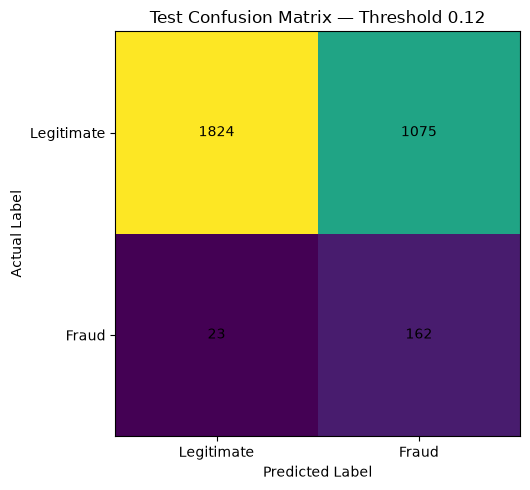

In [24]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, interpolation="nearest")
ax.set_title(f"Test Confusion Matrix — Threshold {selected_threshold:.2f}")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
ax.set_xticks([0, 1], labels=["Legitimate", "Fraud"])
ax.set_yticks([0, 1], labels=["Legitimate", "Fraud"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

## 12. Compare threshold-based policy with Top-K ranking

Our test set contains approximately 20% of the monthly claims, so the monthly investigation capacity of 200 corresponds to **Top-40 claims** in this test set. This comparison shows the difference between a probability cutoff that may flag a variable number of claims and a fixed-capacity ranking policy.

In [25]:
K = 40  # test-set equivalent of 200 investigations per month
top_k_indices = np.argsort(test_prob)[::-1][:K]
top_k_pred = np.zeros(len(test_prob), dtype=int)
top_k_pred[top_k_indices] = 1

threshold_topk_comparison = pd.DataFrame([
    {
        "Policy": f"Threshold >= {selected_threshold:.2f}",
        "Claims_Selected": int(test_pred_selected.sum()),
        "Fraud_Captured": int(((test_pred_selected == 1) & (y_test == 1)).sum()),
        "Precision": precision_score(y_test, test_pred_selected, zero_division=0),
        "Recall": recall_score(y_test, test_pred_selected, zero_division=0)
    },
    {
        "Policy": f"Top-{K} ranking (fixed capacity)",
        "Claims_Selected": int(top_k_pred.sum()),
        "Fraud_Captured": int(((top_k_pred == 1) & (y_test == 1)).sum()),
        "Precision": precision_score(y_test, top_k_pred, zero_division=0),
        "Recall": recall_score(y_test, top_k_pred, zero_division=0)
    }
])
threshold_topk_comparison.round(4)

,Policy,Claims_Selected,Fraud_Captured,Precision,Recall
0,Threshold >= 0.12,1237,162,0.131,0.8757
1,Top-40 ranking (fixed capacity),40,16,0.400,0.0865


## 13. Save the results

Export the threshold analysis and test comparison so we can refer to the results during the next project review.

In [26]:
threshold_results.to_csv(REPORTS_DIR / "threshold_analysis_validation.csv", index=False)
pd.DataFrame([selected_threshold_metrics]).to_csv(REPORTS_DIR / "threshold_selected_test_metrics.csv", index=False)
threshold_topk_comparison.to_csv(REPORTS_DIR / "threshold_vs_topk_test_comparison.csv", index=False)
print("Saved results to:", REPORTS_DIR)

Saved results to: C:\Users\rudra\OneDrive\Documents\insurance-claim-fraud-detection\insurance-claim-fraud-detection\reports
